# Variables e imputaciones

In [1]:
import pandas as pd
import numpy as np

# Semilla fija para que los resultados sean reproducibles
np.random.seed(42)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import confusion_matrix
from xgboost import XGBClassifier

# El dataset (reto_agua.csv) lo facilita el curso y no se incluye completo en este repositorio.
# Coloca el fichero en la carpeta data/ (hay una muestra pequeña en data/muestra_reto_agua.csv).
c = pd.read_csv('data/reto_agua.csv')

df = pd.DataFrame(c)

In [2]:
df_final = df.copy()

In [3]:
# Transformamos las variables a categóricas en el df original:

columns_object = df.loc[:, df.dtypes == object].columns
df[columns_object] = df[columns_object].astype('category')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55083 entries, 0 to 55082
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   id                     55083 non-null  int64   
 1   amount_tsh             55083 non-null  float64 
 2   funder                 51885 non-null  category
 3   gps_height             55083 non-null  int64   
 4   installer              51868 non-null  category
 5   longitude              55083 non-null  float64 
 6   latitude               55083 non-null  float64 
 7   wpt_name               55083 non-null  category
 8   num_private            55083 non-null  int64   
 9   basin                  55083 non-null  category
 10  region                 55083 non-null  category
 11  population             55083 non-null  int64   
 12  public_meeting         51905 non-null  category
 13  recorded_by            55083 non-null  category
 14  scheme_management      51429 non-null 

In [4]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55083 entries, 0 to 55082
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     55083 non-null  int64  
 1   amount_tsh             55083 non-null  float64
 2   funder                 51885 non-null  object 
 3   gps_height             55083 non-null  int64  
 4   installer              51868 non-null  object 
 5   longitude              55083 non-null  float64
 6   latitude               55083 non-null  float64
 7   wpt_name               55083 non-null  object 
 8   num_private            55083 non-null  int64  
 9   basin                  55083 non-null  object 
 10  region                 55083 non-null  object 
 11  population             55083 non-null  int64  
 12  public_meeting         51905 non-null  object 
 13  recorded_by            55083 non-null  object 
 14  scheme_management      51429 non-null  object 
 15  pe

In [5]:
print('Registros duplicados:', df.duplicated().sum())

Registros duplicados: 0


In [6]:
valores_ministerio = df_final[df_final['funder'].str.contains('Ministry',  case=False, na=False)]

print(valores_ministerio['funder'])

182      Ministry Of Water
210      Ministry Of Water
235      Ministry Of Water
389      Ministry Of Water
456      Ministry Of Water
               ...        
54663    Ministry Of Water
54715    Ministry Of Water
54720    Ministry Of Water
54744    Ministry Of Water
54780    Ministry Of Water
Name: funder, Length: 581, dtype: object


In [7]:
valores_ministerio = df_final[df_final['funder'].str.contains('Ministry',  case=False, na=False)]

print(valores_ministerio['funder'])

182      Ministry Of Water
210      Ministry Of Water
235      Ministry Of Water
389      Ministry Of Water
456      Ministry Of Water
               ...        
54663    Ministry Of Water
54715    Ministry Of Water
54720    Ministry Of Water
54744    Ministry Of Water
54780    Ministry Of Water
Name: funder, Length: 581, dtype: object


In [8]:
valores_unicos = valores_ministerio['funder'].unique()

print(valores_unicos)

['Ministry Of Water' 'Health  Ministry' 'Ministry Of Education'
 'Ministry Of Healthy' 'Ministry Of Agricultura']


In [9]:
df_final1 = df_final.copy()

df_final1.dropna(subset=['funder'], inplace=True)

In [10]:
condicion_gobierno = (df_final1['funder'] == 'Government Of Tanzania') | (df_final1['funder'].str.contains('Ministry', case=False, na=False))

In [11]:
df_final1['funder'] = np.where(condicion_gobierno, 'Gobierno', 'No gubernamental')

valores_frecuencia = df_final1["funder"].value_counts()

valores_frecuencia

No gubernamental    42921
Gobierno             8964
Name: funder, dtype: int64

In [12]:
df_final1

,id,amount_tsh,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,...,construction_year,extraction_type,management_group,payment_type,water_quality,quality_group,quantity_group,source_class,waterpoint_type_group,status_group
0,69572,6000.0,No gubernamental,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,...,1999,gravity,user-group,annually,soft,good,enough,groundwater,communal standpipe,functional
1,8776,0.0,No gubernamental,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,...,2010,gravity,user-group,never pay,soft,good,insufficient,surface,communal standpipe,functional
2,34310,25.0,No gubernamental,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,...,2009,gravity,user-group,per bucket,soft,good,enough,surface,communal standpipe,functional
3,67743,0.0,No gubernamental,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,...,1986,submersible,user-group,never pay,soft,good,dry,groundwater,communal standpipe,non functional
4,19728,0.0,No gubernamental,0,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,...,0,gravity,other,never pay,soft,good,seasonal,surface,communal standpipe,functional
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55077,11164,500.0,No gubernamental,351,ML appro,37.634053,-6.124830,Chimeredya,0,Wami / Ruvu,...,2007,submersible,user-group,monthly,soft,good,enough,groundwater,communal standpipe,non functional
55078,60739,10.0,No gubernamental,1210,CES,37.169807,-3.253847,Area Three Namba 27,0,Pangani,...,1999,gravity,user-group,per bucket,soft,good,enough,groundwater,communal standpipe,functional
55079,27263,4700.0,No gubernamental,1212,Cefa,35.249991,-9.070629,Kwa Yahona Kuvala,0,Rufiji,...,1996,gravity,user-group,annually,soft,good,enough,surface,communal standpipe,functional
55081,31282,0.0,No gubernamental,0,Musa,35.861315,-6.378573,Mshoro,0,Rufiji,...,0,nira/tanira,user-group,never pay,soft,good,insufficient,groundwater,hand pump,functional


In [13]:
df_final1['funder'].value_counts()

No gubernamental    42921
Gobierno             8964
Name: funder, dtype: int64

In [14]:
df_final1['public_meeting'].value_counts()

True     44610
False     4286
Name: public_meeting, dtype: int64

In [15]:
df_final1.isna().sum()

id                          0
amount_tsh                  0
funder                      0
gps_height                  0
installer                  70
longitude                   0
latitude                    0
wpt_name                    0
num_private                 0
basin                       0
region                      0
population                  0
public_meeting           2989
recorded_by                 0
scheme_management        3617
permit                    597
construction_year           0
extraction_type             0
management_group            0
payment_type                0
water_quality               0
quality_group               0
quantity_group              0
source_class                0
waterpoint_type_group       0
status_group                0
dtype: int64

In [16]:
df_final1.dropna(subset=['public_meeting'], inplace=True)

In [17]:
df_final1.isna().sum()

id                          0
amount_tsh                  0
funder                      0
gps_height                  0
installer                  50
longitude                   0
latitude                    0
wpt_name                    0
num_private                 0
basin                       0
region                      0
population                  0
public_meeting              0
recorded_by                 0
scheme_management        3247
permit                    483
construction_year           0
extraction_type             0
management_group            0
payment_type                0
water_quality               0
quality_group               0
quantity_group              0
source_class                0
waterpoint_type_group       0
status_group                0
dtype: int64

In [18]:
df_final1.dropna(subset=['installer'], inplace=True)

In [19]:
df_final1.dropna(subset=['permit'], inplace=True)

In [20]:
df_final1['construction_year'] = df_final1['construction_year'].replace(0, np.nan)

In [21]:
df_final1['construction_year'].fillna(df_final1['construction_year'].median(), inplace=True)

In [22]:
df_final1.isna().sum()

id                          0
amount_tsh                  0
funder                      0
gps_height                  0
installer                   0
longitude                   0
latitude                    0
wpt_name                    0
num_private                 0
basin                       0
region                      0
population                  0
public_meeting              0
recorded_by                 0
scheme_management        3216
permit                      0
construction_year           0
extraction_type             0
management_group            0
payment_type                0
water_quality               0
quality_group               0
quantity_group              0
source_class                0
waterpoint_type_group       0
status_group                0
dtype: int64

In [23]:
df_final1['status_group_d'] = df_final1['status_group'].replace({'functional': 1, 'non functional': 0})

#Nueva columna dicotómica de la target

In [24]:
std_gps_height = np.std(df_final1.loc[df_final1['gps_height'] != 0, 'gps_height'])
median_gps_height = np.median(df_final1.loc[df_final1['gps_height'] != 0, 'gps_height'])
random_values = np.random.normal(median_gps_height, std_gps_height, len(df_final1))
df_final1['gps_height'] = df_final1['gps_height'].astype(float)  # permite imputar valores decimales
df_final1.loc[df_final1['gps_height'] == 0, 'gps_height'] = random_values[df_final1['gps_height'] == 0]
df_final1

,id,amount_tsh,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,...,extraction_type,management_group,payment_type,water_quality,quality_group,quantity_group,source_class,waterpoint_type_group,status_group,status_group_d
0,69572,6000.0,No gubernamental,1390.000000,Roman,34.938093,-9.856322,none,0,Lake Nyasa,...,gravity,user-group,annually,soft,good,enough,groundwater,communal standpipe,functional,1
2,34310,25.0,No gubernamental,686.000000,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,...,gravity,user-group,per bucket,soft,good,enough,surface,communal standpipe,functional,1
3,67743,0.0,No gubernamental,263.000000,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,...,submersible,user-group,never pay,soft,good,dry,groundwater,communal standpipe,non functional,0
4,19728,0.0,No gubernamental,2090.300893,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,...,gravity,other,never pay,soft,good,seasonal,surface,communal standpipe,functional,1
5,9944,20.0,No gubernamental,992.745274,DWE,39.172796,-4.765587,Tajiri,0,Pangani,...,submersible,user-group,per bucket,salty,salty,enough,unknown,communal standpipe,functional,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55077,11164,500.0,No gubernamental,351.000000,ML appro,37.634053,-6.124830,Chimeredya,0,Wami / Ruvu,...,submersible,user-group,monthly,soft,good,enough,groundwater,communal standpipe,non functional,0
55078,60739,10.0,No gubernamental,1210.000000,CES,37.169807,-3.253847,Area Three Namba 27,0,Pangani,...,gravity,user-group,per bucket,soft,good,enough,groundwater,communal standpipe,functional,1
55079,27263,4700.0,No gubernamental,1212.000000,Cefa,35.249991,-9.070629,Kwa Yahona Kuvala,0,Rufiji,...,gravity,user-group,annually,soft,good,enough,surface,communal standpipe,functional,1
55081,31282,0.0,No gubernamental,242.034211,Musa,35.861315,-6.378573,Mshoro,0,Rufiji,...,nira/tanira,user-group,never pay,soft,good,insufficient,groundwater,hand pump,functional,1


In [25]:
df_final1.corr()

,id,amount_tsh,gps_height,longitude,latitude,num_private,population,construction_year,status_group_d
id,1.000000,-0.006556,-0.000664,-0.009593,0.006570,-0.002274,-0.005911,-0.004045,-0.002483
amount_tsh,-0.006556,1.000000,0.029539,0.021788,-0.067537,0.002307,0.014591,-0.003954,0.062414
gps_height,-0.000664,0.029539,1.000000,-0.209587,0.187297,-0.016368,-0.086522,0.019461,0.115210
longitude,-0.009593,0.021788,-0.209587,1.000000,-0.406422,0.026059,0.080456,-0.051175,0.000748
latitude,0.006570,-0.067537,0.187297,-0.406422,1.000000,0.008970,-0.056239,0.082000,0.021136
num_private,-0.002274,0.002307,-0.016368,0.026059,0.008970,1.000000,0.004868,-0.006830,0.004711
population,-0.005911,0.014591,-0.086522,0.080456,-0.056239,0.004868,1.000000,-0.012940,0.015096
construction_year,-0.004045,-0.003954,0.019461,-0.051175,0.082000,-0.006830,-0.012940,1.000000,0.218069
status_group_d,-0.002483,0.062414,0.115210,0.000748,0.021136,0.004711,0.015096,0.218069,1.000000


In [26]:
df_21 = df_final1.copy()

In [27]:
df_final1.drop(['population', 'scheme_management','wpt_name','num_private','recorded_by','waterpoint_type_group','source_class','quality_group','id','amount_tsh','water_quality'], axis=1, inplace=True)

In [28]:
df_encoder = df_final1.copy()

In [29]:
df_encoder['funder'] = df_encoder['funder'].replace({'No gubernamental': 1, 'Gobierno': 0})

In [30]:
df_encoder.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 48368 entries, 0 to 55082
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   funder             48368 non-null  int64  
 1   gps_height         48368 non-null  float64
 2   installer          48368 non-null  object 
 3   longitude          48368 non-null  float64
 4   latitude           48368 non-null  float64
 5   basin              48368 non-null  object 
 6   region             48368 non-null  object 
 7   public_meeting     48368 non-null  object 
 8   permit             48368 non-null  object 
 9   construction_year  48368 non-null  float64
 10  extraction_type    48368 non-null  object 
 11  management_group   48368 non-null  object 
 12  payment_type       48368 non-null  object 
 13  quantity_group     48368 non-null  object 
 14  status_group       48368 non-null  object 
 15  status_group_d     48368 non-null  int64  
dtypes: float64(4), int64(2

In [31]:
df_encoder['basin'] = df_encoder['basin'].astype('category')
df_encoder['basin'] = df_encoder['basin'].cat.codes

df_encoder['region'] = df_encoder['region'].astype('category')
df_encoder['region'] = df_encoder['region'].cat.codes

df_encoder['public_meeting'] = df_encoder['public_meeting'].replace({True: 1, False: 0})
df_encoder['permit'] = df_encoder['permit'].replace({True: 1, False: 0})


df_encoder['extraction_type'] = df_encoder['extraction_type'].astype('category')
df_encoder['extraction_type'] = df_encoder['extraction_type'].cat.codes


df_encoder['management_group'] = df_encoder['management_group'].astype('category')
df_encoder['management_group'] = df_encoder['management_group'].cat.codes

df_encoder['payment_type'] = df_encoder['payment_type'].astype('category')
df_encoder['payment_type'] = df_encoder['payment_type'].cat.codes

df_encoder['quantity_group'] = df_encoder['quantity_group'].astype('category')
df_encoder['quantity_group'] = df_encoder['quantity_group'].cat.codes

In [32]:
df_encoder.corr(method = 'pearson')

,funder,gps_height,longitude,latitude,basin,region,public_meeting,permit,construction_year,extraction_type,management_group,payment_type,quantity_group,status_group_d
funder,1.000000,-0.013865,-0.022376,-0.124934,-0.004400,0.049801,0.012808,-0.017874,0.296049,0.097579,-0.021953,-0.006120,-0.015758,0.134100
gps_height,-0.013865,1.000000,-0.209587,0.187297,-0.419090,-0.274778,0.039993,0.020604,0.019461,-0.232920,0.097390,-0.120668,-0.032324,0.115210
longitude,-0.022376,-0.209587,1.000000,-0.406422,0.262452,-0.085264,0.016144,0.027335,-0.051175,-0.000285,-0.077015,0.045536,0.020153,0.000748
latitude,-0.124934,0.187297,-0.406422,1.000000,-0.255252,-0.031564,0.040323,0.125801,0.082000,-0.058909,-0.046558,0.170856,0.129126,0.021136
basin,-0.004400,-0.419090,0.262452,-0.255252,1.000000,-0.072049,0.034944,0.069078,-0.089196,0.162219,-0.061870,0.020743,-0.028538,-0.057661
region,0.049801,-0.274778,-0.085264,-0.031564,-0.072049,1.000000,-0.128198,-0.041939,-0.046432,0.238393,-0.060629,0.006733,0.048437,-0.094581
public_meeting,0.012808,0.039993,0.016144,0.040323,0.034944,-0.128198,1.000000,0.144838,0.031208,-0.044128,0.217188,-0.082672,-0.054132,0.082231
permit,-0.017874,0.020604,0.027335,0.125801,0.069078,-0.041939,0.144838,1.000000,-0.034942,-0.104029,-0.031343,-0.041142,-0.036764,0.049141
construction_year,0.296049,0.019461,-0.051175,0.082000,-0.089196,-0.046432,0.031208,-0.034942,1.000000,0.029024,-0.062499,0.098907,0.020121,0.218069
extraction_type,0.097579,-0.232920,-0.000285,-0.058909,0.162219,0.238393,-0.044128,-0.104029,0.029024,1.000000,-0.004423,0.114891,0.017435,-0.128968


In [33]:
df_encoder.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 48368 entries, 0 to 55082
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   funder             48368 non-null  int64  
 1   gps_height         48368 non-null  float64
 2   installer          48368 non-null  object 
 3   longitude          48368 non-null  float64
 4   latitude           48368 non-null  float64
 5   basin              48368 non-null  int8   
 6   region             48368 non-null  int8   
 7   public_meeting     48368 non-null  int64  
 8   permit             48368 non-null  int64  
 9   construction_year  48368 non-null  float64
 10  extraction_type    48368 non-null  int8   
 11  management_group   48368 non-null  int8   
 12  payment_type       48368 non-null  int8   
 13  quantity_group     48368 non-null  int8   
 14  status_group       48368 non-null  object 
 15  status_group_d     48368 non-null  int64  
dtypes: float64(4), int64(4

In [34]:
df_encoder.drop(['installer'], axis=1, inplace=True)

In [35]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df_encoder.corr(), annot=True, ax=ax, cmap="coolwarm")

plt.show()

<Figure size 1000x800 with 2 Axes>

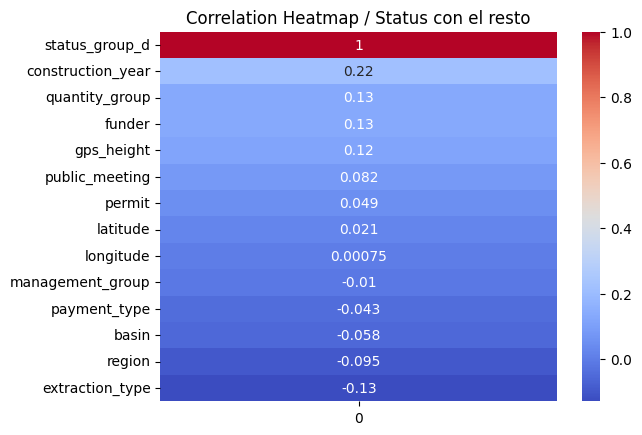

In [36]:
correlation_matrix = df_encoder.corrwith(df_encoder['status_group_d'])

sorted_corr = correlation_matrix.sort_values(ascending=False)

sns.heatmap(sorted_corr.to_frame(), annot=True, cmap="coolwarm")
plt.title('Correlation Heatmap / Status con el resto')
plt.show()

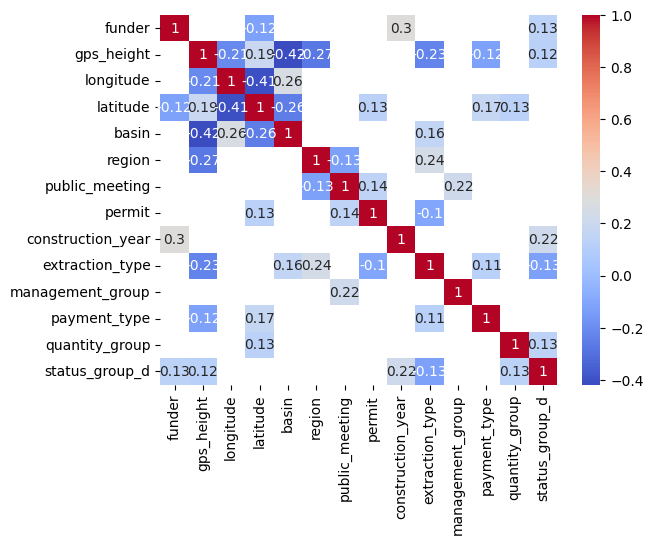

<Figure size 1000x800 with 0 Axes>

In [37]:
corr = df_encoder.corr()
mask = (corr > 0.10) | (corr < -0.10)

sns.heatmap(corr[mask], annot=True, cmap="coolwarm")
plt.figure(figsize=(10, 8))

plt.show()

# Ejercicio 2

In [38]:
df_f = df_encoder.copy()

In [39]:
df_f.drop(['status_group','status_group_d'], axis=1, inplace=True)

In [40]:
df_f.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 48368 entries, 0 to 55082
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   funder             48368 non-null  int64  
 1   gps_height         48368 non-null  float64
 2   longitude          48368 non-null  float64
 3   latitude           48368 non-null  float64
 4   basin              48368 non-null  int8   
 5   region             48368 non-null  int8   
 6   public_meeting     48368 non-null  int64  
 7   permit             48368 non-null  int64  
 8   construction_year  48368 non-null  float64
 9   extraction_type    48368 non-null  int8   
 10  management_group   48368 non-null  int8   
 11  payment_type       48368 non-null  int8   
 12  quantity_group     48368 non-null  int8   
dtypes: float64(4), int64(3), int8(6)
memory usage: 3.2 MB


In [41]:
df_u = df_encoder.copy()

In [42]:
df_u = df_u[['construction_year','gps_height','quantity_group','funder','extraction_type']]

In [43]:
target = df_encoder.copy()

In [44]:
target = target['status_group_d']

## Modelos con las variables seleccionadas

### Reg logística

In [45]:
X = df_f
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Crear una instancia del modelo de regresión logística
logistic_model = LogisticRegression()

# Entrenar el modelo con los datos de entrenamiento
logistic_model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predictions = logistic_model.predict(X_test)

# Calcular la exactitud (accuracy) del modelo
accuracy = accuracy_score(y_test, predictions)
print("Exactitud (Accuracy):", accuracy)

# Calcular la precisión, la exhaustividad (recall) y la puntuación F1
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

print("Precisión:", precision)
print("Exhaustividad (Recall):", recall)
print("Puntuación F1:", f1)


Exactitud (Accuracy): 0.664358073185859
Precisión: 0.6725237352982854
Exhaustividad (Recall): 0.8352692713833157
Puntuación F1: 0.7451134311955413


In [46]:
from sklearn.metrics import confusion_matrix

# Calcular la matriz de confusión
confusion_matrix = confusion_matrix(y_test, predictions)

print("Matriz de Confusión:")
print(confusion_matrix)

Matriz de Confusión:
[[1681 2311]
 [ 936 4746]]


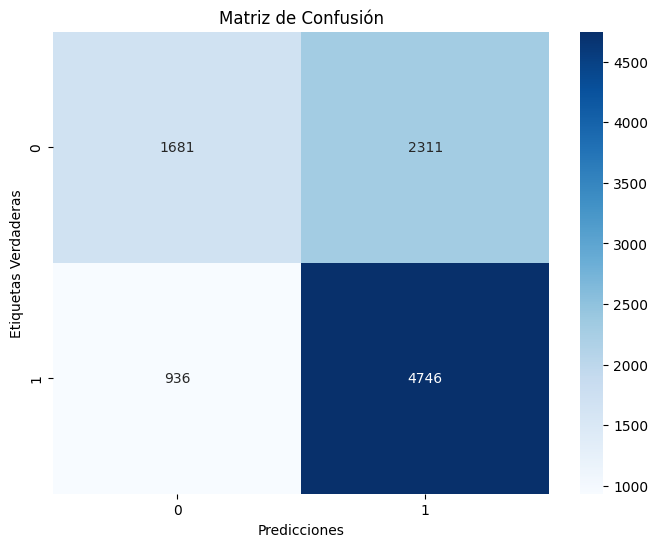

In [47]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt="d", cmap="Blues")

# Configurar etiquetas de los ejes
plt.xlabel("Predicciones")
plt.ylabel("Etiquetas Verdaderas")
plt.title("Matriz de Confusión")

# Mostrar la figura
plt.show()

### Árbol de decisión

In [48]:
X = df_f
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Crear una instancia del modelo de árbol de decisión
tree_model = DecisionTreeClassifier()

# Entrenar el modelo con los datos de entrenamiento
tree_model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predictions = tree_model.predict(X_test)

# Calcular la exactitud (accuracy) del modelo
accuracy_a = accuracy_score(y_test, predictions)
print("Exactitud_a (Accuracy):", accuracy_a)

# Calcular la precisión, la exhaustividad (recall) y la puntuación F1
precision_a = precision_score(y_test, predictions)
recall_a = recall_score(y_test, predictions)
f1_a = f1_score(y_test, predictions)

print("Precisión_a:", precision_a)
print("Exhaustividad_a (Recall):", recall_a)
print("Puntuación F1_a:", f1_a)


Exactitud_a (Accuracy): 0.8040107504651643
Precisión_a: 0.8335095137420718
Exhaustividad_a (Recall): 0.8326293558606125
Puntuación F1_a: 0.8330692023243529


In [49]:
from sklearn.metrics import confusion_matrix

# Calcular la matriz de confusión
confusion_matrix_t = confusion_matrix(y_test, predictions)

print("Matriz de Confusión:")
print(confusion_matrix_t)

Matriz de Confusión:
[[3047  945]
 [ 951 4731]]


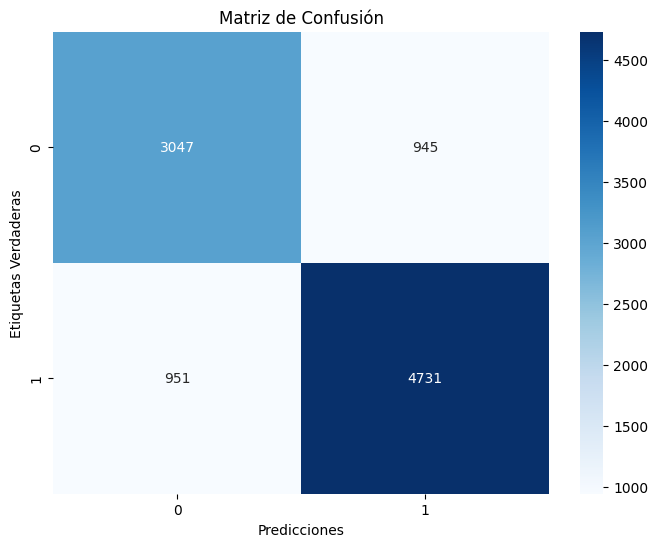

In [50]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix_t, annot=True, fmt="d", cmap="Blues")

# Configurar etiquetas de los ejes
plt.xlabel("Predicciones")
plt.ylabel("Etiquetas Verdaderas")
plt.title("Matriz de Confusión")

# Mostrar la figura
plt.show()

### RandomForest

In [51]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

X = df_f
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Crear una instancia del modelo de Random Forest
rf_model = RandomForestClassifier()

# Entrenar el modelo con los datos de entrenamiento
rf_model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predictions = rf_model.predict(X_test)

# Calcular la exactitud (accuracy) del modelo
accuracy_rf = accuracy_score(y_test, predictions)
print("Exactitud_rf (Accuracy):", accuracy_rf)

# Calcular la precisión, la exhaustividad (recall) y la puntuación F1
precision_rf = precision_score(y_test, predictions)
recall_rf = recall_score(y_test, predictions)
f1_rf = f1_score(y_test, predictions)

print("Precisión_rf:", precision_rf)
print("Exhaustividad_rf (Recall):", recall_rf)
print("Puntuación F1_rf:", f1_rf)

Exactitud_rf (Accuracy): 0.8438081455447591
Precisión_rf: 0.8518643495866374
Exhaustividad_rf (Recall): 0.8885955649419218
Puntuación F1_rf: 0.8698423636833491


In [52]:
from sklearn.metrics import confusion_matrix

# Calcular la matriz de confusión
confusion_matrix_rf = confusion_matrix(y_test, predictions)

print("Matriz de Confusión:")
print(confusion_matrix_rf)

Matriz de Confusión:
[[3114  878]
 [ 633 5049]]


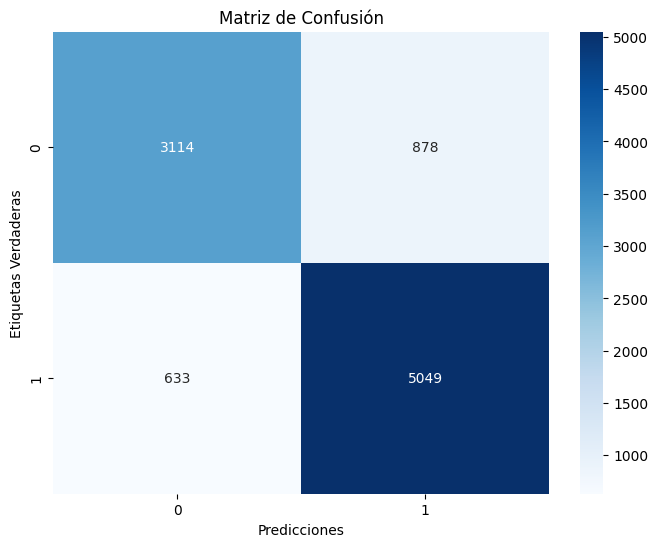

In [53]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix_rf, annot=True, fmt="d", cmap="Blues")

# Configurar etiquetas de los ejes
plt.xlabel("Predicciones")
plt.ylabel("Etiquetas Verdaderas")
plt.title("Matriz de Confusión")

# Mostrar la figura
plt.show()

### XGB 

In [54]:
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

X = df_f
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Crear una instancia del modelo XGBoost Classifier
xgb_model = XGBClassifier()

# Entrenar el modelo con los datos de entrenamiento
xgb_model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predictions = xgb_model.predict(X_test)

# Calcular la exactitud (accuracy) del modelo
accuracy_xgb = accuracy_score(y_test, predictions)
print("Exactitud_xgb (Accuracy):", accuracy_xgb)

# Calcular la precisión, la exhaustividad (recall) y la puntuación F1
precision_xgb = precision_score(y_test, predictions)
recall_xgb = recall_score(y_test, predictions)
f1_xgb = f1_score(y_test, predictions)

print("Precisión_xgb:", precision_xgb)
print("Exhaustividad_xgb (Recall):", recall_xgb)
print("Puntuación F1_xgb:", f1_xgb)

Exactitud_xgb (Accuracy): 0.8320239818069051
Precisión_xgb: 0.82596818254861
Exhaustividad_xgb (Recall): 0.9046110524463217
Puntuación F1_xgb: 0.8635027299454012


In [55]:
from sklearn.metrics import confusion_matrix

# Calcular la matriz de confusión
confusion_matrix_xgb = confusion_matrix(y_test, predictions)

print("Matriz de Confusión:")
print(confusion_matrix_xgb)

Matriz de Confusión:
[[2909 1083]
 [ 542 5140]]


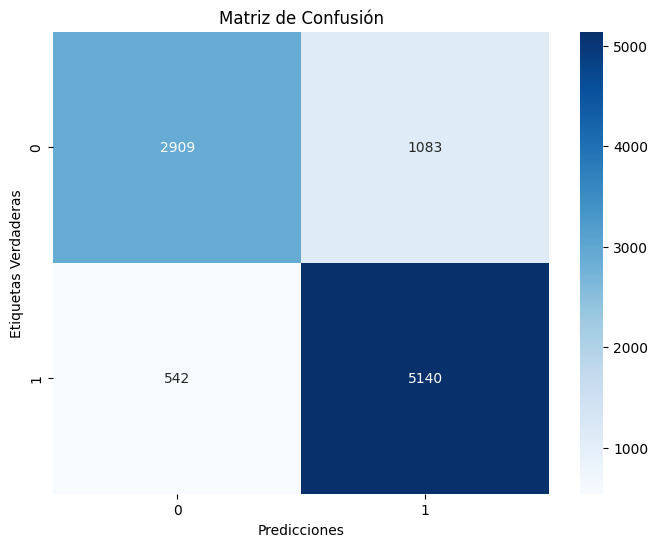

In [56]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix_xgb, annot=True, fmt="d", cmap="Blues")

# Configurar etiquetas de los ejes
plt.xlabel("Predicciones")
plt.ylabel("Etiquetas Verdaderas")
plt.title("Matriz de Confusión")

# Mostrar la figura
plt.show()

In [57]:
X = df_f
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

xgb_model = XGBClassifier()

xgb_model.fit(X_train, y_train)

# Predecir el conjunto de train
predictions_train = xgb_model.predict(X_train)

accuracy_xgb_train = accuracy_score(y_train, predictions_train)
print("Exactitud_xgb (Accuracy) (conjunto de entrenamiento):", accuracy_xgb_train)

precision_xgb_train = precision_score(y_train, predictions_train)
recall_xgb_train = recall_score(y_train, predictions_train)
f1_xgb_train = f1_score(y_train, predictions_train)

print("Precisión_xgb (conjunto de entrenamiento):", precision_xgb_train)
print("Exhaustividad_xgb (Recall) (conjunto de entrenamiento):", recall_xgb_train)
print("Puntuación F1_xgb (conjunto de entrenamiento):", f1_xgb_train)

Exactitud_xgb (Accuracy) (conjunto de entrenamiento): 0.8806016436656846
Precisión_xgb (conjunto de entrenamiento): 0.8625862345579978
Exhaustividad_xgb (Recall) (conjunto de entrenamiento): 0.9474008810572687
Puntuación F1_xgb (conjunto de entrenamiento): 0.9030063822640243


In [58]:
from sklearn.metrics import confusion_matrix

# Calcular la matriz de confusión
confusion_matrix_xgb_train = confusion_matrix(y_train, predictions_train)

print("Matriz de Confusión:")
print(confusion_matrix_xgb_train)

Matriz de Confusión:
[[12568  3426]
 [ 1194 21506]]


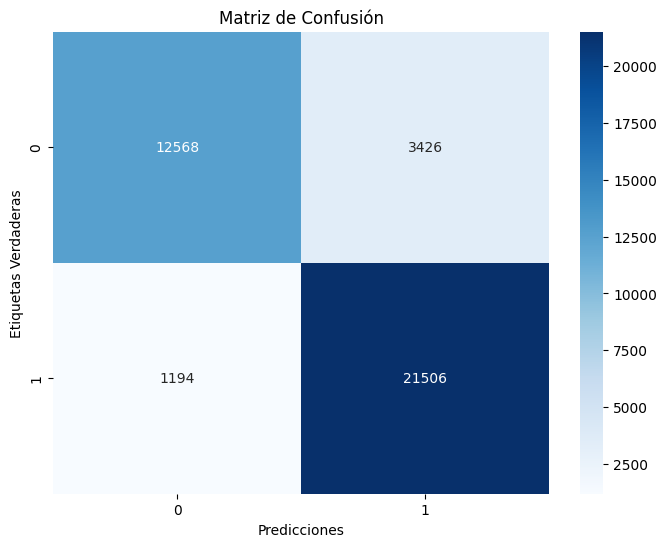

In [59]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix_xgb_train, annot=True, fmt="d", cmap="Blues")

# Configurar etiquetas de los ejes
plt.xlabel("Predicciones")
plt.ylabel("Etiquetas Verdaderas")
plt.title("Matriz de Confusión")

# Mostrar la figura
plt.show()

In [60]:
# Crear un diccionario con los datos
data = {
    'Métrica': ['Accuracy', 'Precision', 'Recall', 'F1'],
    'Train': [accuracy_xgb_train, precision_xgb_train, recall_xgb_train, f1_xgb_train],
    'Test': [accuracy_xgb, precision_xgb, recall_xgb, f1_xgb]
}

df_metrics_t_t = pd.DataFrame(data)

df_metrics_t_t['Métrica'] = 'XGBoost - ' + df_metrics_t_t['Métrica']

df_metrics_t_t

,Métrica,Train,Test
0,XGBoost - Accuracy,0.880602,0.832024
1,XGBoost - Precision,0.862586,0.825968
2,XGBoost - Recall,0.947401,0.904611
3,XGBoost - F1,0.903006,0.863503


In [61]:
# from sklearn.model_selection import GridSearchCV
# from xgboost import XGBClassifier
# 
# xgb_model = XGBClassifier()
# 
# parameters = {
#     'max_depth': [ 5, 7,9, 10] 
#     'learning_rate': [0.2, 0.3, 0.4],
#     'n_estimators': [300, 500, 600],
#     'subsample': [0.8, 0.9, 1], = 1
#     'colsample_bytree': [0.5, 0.7, 0.9]
# 
# }
# 
# grid_search = GridSearchCV(estimator=xgb_model, param_grid=parameters, cv=5, scoring='accuracy')
# 
# grid_search.fit(X_train, y_train)
# 
# best_params = grid_search.best_params_
# print("Mejores hiperparámetros:", best_params)
# 
# best_model = grid_search.best_estimator_
# 
# predictions = best_model.predict(X_test)
# 
# accuracy = accuracy_score(y_test, predictions)
# print("Precisión:", accuracy)

In [62]:
# HIPERPARÁMETROS SELECCIONADOS POR GRIDSEARCH
    # 'max_depth': [3, 5, 7, 10] = 9
    # 'learning_rate': [0.01, 0.05, 0.1], = 0.3
    # 'n_estimators': [100, 200, 300, 500], = 500
    # 'subsample': [0.5, 0.7, 0.9], = 1
    # 'colsample_bytree': [0.5, 0.7, 0.9] = 0.7

In [63]:
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

X = df_f
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

xgb_model = XGBClassifier(max_depth=9, learning_rate=0.3, n_estimators=500, subsample=0.9,colsample_bytree = 0.7)

xgb_model.fit(X_train, y_train)

predictions = xgb_model.predict(X_test)

accuracy_xgb = accuracy_score(y_test, predictions)
print("Exactitud_xgb (Accuracy):", accuracy_xgb)

precision_xgb = precision_score(y_test, predictions)
recall_xgb = recall_score(y_test, predictions)
f1_xgb = f1_score(y_test, predictions)

print("Precisión_xgb:", precision_xgb)
print("Exhaustividad_xgb (Recall):", recall_xgb)
print("Puntuación F1_xgb:", f1_xgb)

Exactitud_xgb (Accuracy): 0.8376059541037834
Precisión_xgb: 0.8457527333894028
Exhaustividad_xgb (Recall): 0.8848996832101372
Puntuación F1_xgb: 0.8648834609099509


In [64]:
    # 'max_depth': [3, 5, 7, 10] = 9
    # 'learning_rate': [0.01, 0.05, 0.1], = 0.3
    # 'n_estimators': [100, 200, 300, 500], = 500
    # 'subsample': [0.5, 0.7, 0.9], = 1
    # 'colsample_bytree': [0.5, 0.7, 0.9] = 0.7

## Resultados

In [65]:
# Calcular las métricas para cada modelo
metrics = {
    "Modelo": ["Regresión Logística", "Árbol de Decisión", "Random Forest", "XGBoost"],
    "Precisión": [precision,precision_a, precision_rf, precision_xgb],
    "Recall": [recall,recall_a, recall_rf, recall_xgb],
    "F1": [f1,f1_a, f1_rf, f1_xgb],
    "Exactitud": [accuracy,accuracy_a, accuracy_rf, accuracy_xgb]
}

# Crear el DataFrame a partir del diccionario de métricas
df_metrics = pd.DataFrame(metrics)

# Imprimir el DataFrame
df_metrics

,Modelo,Precisión,Recall,F1,Exactitud
0,Regresión Logística,0.672524,0.835269,0.745113,0.664358
1,Árbol de Decisión,0.833510,0.832629,0.833069,0.804011
2,Random Forest,0.851864,0.888596,0.869842,0.843808
3,XGBoost,0.845753,0.884900,0.864883,0.837606


## Mejores variables

In [66]:
# MEJORES CORR
X = df_u
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Crear una instancia del modelo de regresión logística
logistic_model = LogisticRegression()

# Entrenar el modelo con los datos de entrenamiento
logistic_model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predictions = logistic_model.predict(X_test)

# Calcular la exactitud (accuracy) del modelo
accuracy = accuracy_score(y_test, predictions)
print("Exactitud (Accuracy):", accuracy)

# Calcular la precisión, la exhaustividad (recall) y la puntuación F1
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

print("Precisión:", precision)
print("Exhaustividad (Recall):", recall)
print("Puntuación F1:", f1)

Exactitud (Accuracy): 0.6596030597477776
Precisión: 0.6682157442613716
Exhaustividad (Recall): 0.8350932770151355
Puntuación F1: 0.7423922396933427


In [67]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

X = df_u
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Crear una instancia del modelo de árbol de decisión
tree_model = DecisionTreeClassifier()

# Entrenar el modelo con los datos de entrenamiento
tree_model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predictions = tree_model.predict(X_test)

# Calcular la exactitud (accuracy) del modelo
accuracy_a = accuracy_score(y_test, predictions)
print("Exactitud_a (Accuracy):", accuracy_a)

# Calcular la precisión, la exhaustividad (recall) y la puntuación F1
precision_a = precision_score(y_test, predictions)
recall_a = recall_score(y_test, predictions)
f1_a = f1_score(y_test, predictions)

print("Precisión_a:", precision_a)
print("Exhaustividad_a (Recall):", recall_a)
print("Puntuación F1_a:", f1_a)


Exactitud_a (Accuracy): 0.732065329749845
Precisión_a: 0.7729681978798587
Exhaustividad_a (Recall): 0.7699753607884547
Puntuación F1_a: 0.7714688767413154


In [68]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

X = df_u
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Crear una instancia del modelo de Random Forest
rf_model = RandomForestClassifier()

# Entrenar el modelo con los datos de entrenamiento
rf_model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predictions = rf_model.predict(X_test)

# Calcular la exactitud (accuracy) del modelo
accuracy_rf = accuracy_score(y_test, predictions)
print("Exactitud_rf (Accuracy):", accuracy_rf)

# Calcular la precisión, la exhaustividad (recall) y la puntuación F1
precision_rf = precision_score(y_test, predictions)
recall_rf = recall_score(y_test, predictions)
f1_rf = f1_score(y_test, predictions)

print("Precisión_rf:", precision_rf)
print("Exhaustividad_rf (Recall):", recall_rf)
print("Puntuación F1_rf:", f1_rf)

Exactitud_rf (Accuracy): 0.7526359313624147
Precisión_rf: 0.7859502695183447
Exhaustividad_rf (Recall): 0.7954945441745864
Puntuación F1_rf: 0.7906936062275869


In [69]:
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

X = df_u
y = target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dividir los datos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Crear una instancia del modelo XGBoost Classifier
xgb_model = XGBClassifier()

# Entrenar el modelo con los datos de entrenamiento
xgb_model.fit(X_train, y_train)

# Realizar predicciones en el conjunto de prueba
predictions = xgb_model.predict(X_test)

# Calcular la exactitud (accuracy) del modelo
accuracy_xgb = accuracy_score(y_test, predictions)
print("Exactitud_xgb (Accuracy):", accuracy_xgb)

# Calcular la precisión, la exhaustividad (recall) y la puntuación F1
precision_xgb = precision_score(y_test, predictions)
recall_xgb = recall_score(y_test, predictions)
f1_xgb = f1_score(y_test, predictions)

print("Precisión_xgb:", precision_xgb)
print("Exhaustividad_xgb (Recall):", recall_xgb)
print("Puntuación F1_xgb:", f1_xgb)
#PINTURITA

Exactitud_xgb (Accuracy): 0.7862311350010337
Precisión_xgb: 0.7701046337817639
Exhaustividad_xgb (Recall): 0.9067229848644843
Puntuación F1_xgb: 0.832848367280957


In [70]:
import pandas as pd

# Calcular las métricas para cada modelo
metrics = {
    "Modelo_mv": ["Regresión Logística", "Árbol de Decisión", "Random Forest", "XGBoost"],
    "Precisión_mv": [precision,precision_a, precision_rf, precision_xgb],
    "Recall_mv": [recall,recall_a, recall_rf, recall_xgb],
    "F1_mv": [f1,f1_a, f1_rf, f1_xgb],
    "Exactitud_mv": [accuracy,accuracy_a, accuracy_rf, accuracy_xgb]
}

# Crear el DataFrame a partir del diccionario de métricas
df_metrics2 = pd.DataFrame(metrics)

# Imprimir el DataFrame
df_metrics2

,Modelo_mv,Precisión_mv,Recall_mv,F1_mv,Exactitud_mv
0,Regresión Logística,0.668216,0.835093,0.742392,0.659603
1,Árbol de Decisión,0.772968,0.769975,0.771469,0.732065
2,Random Forest,0.785950,0.795495,0.790694,0.752636
3,XGBoost,0.770105,0.906723,0.832848,0.786231


In [71]:
df_metrics

,Modelo,Precisión,Recall,F1,Exactitud
0,Regresión Logística,0.672524,0.835269,0.745113,0.664358
1,Árbol de Decisión,0.833510,0.832629,0.833069,0.804011
2,Random Forest,0.851864,0.888596,0.869842,0.843808
3,XGBoost,0.845753,0.884900,0.864883,0.837606


# Ejercicio 3

In [72]:
df_21.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 48368 entries, 0 to 55082
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     48368 non-null  int64  
 1   amount_tsh             48368 non-null  float64
 2   funder                 48368 non-null  object 
 3   gps_height             48368 non-null  float64
 4   installer              48368 non-null  object 
 5   longitude              48368 non-null  float64
 6   latitude               48368 non-null  float64
 7   wpt_name               48368 non-null  object 
 8   num_private            48368 non-null  int64  
 9   basin                  48368 non-null  object 
 10  region                 48368 non-null  object 
 11  population             48368 non-null  int64  
 12  public_meeting         48368 non-null  object 
 13  recorded_by            48368 non-null  object 
 14  scheme_management      45152 non-null  object 
 15  pe

In [73]:
df_21.drop(['wpt_name','num_private','recorded_by','id'], axis=1, inplace=True)

In [74]:
df_21.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 48368 entries, 0 to 55082
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   amount_tsh             48368 non-null  float64
 1   funder                 48368 non-null  object 
 2   gps_height             48368 non-null  float64
 3   installer              48368 non-null  object 
 4   longitude              48368 non-null  float64
 5   latitude               48368 non-null  float64
 6   basin                  48368 non-null  object 
 7   region                 48368 non-null  object 
 8   population             48368 non-null  int64  
 9   public_meeting         48368 non-null  object 
 10  scheme_management      45152 non-null  object 
 11  permit                 48368 non-null  object 
 12  construction_year      48368 non-null  float64
 13  extraction_type        48368 non-null  object 
 14  management_group       48368 non-null  object 
 15  pa

In [75]:
df_21['basin'] = df_21['basin'].astype('category')
df_21['basin'] = df_21['basin'].cat.codes

df_21['region'] = df_21['region'].astype('category')
df_21['region'] = df_21['region'].cat.codes
df_21['public_meeting'] = df_21['public_meeting'].replace({True: 1, False: 0})
df_21['permit'] = df_21['permit'].replace({True: 1, False: 0})


df_21['extraction_type'] = df_21['extraction_type'].astype('category')
df_21['extraction_type'] = df_21['extraction_type'].cat.codes

df_21['scheme_management'] = df_21['scheme_management'].astype('category')
df_21['scheme_management'] = df_21['scheme_management'].cat.codes

df_21['management_group'] = df_21['management_group'].astype('category')
df_21['management_group'] = df_21['management_group'].cat.codes

df_21['payment_type'] = df_21['payment_type'].astype('category')
df_21['payment_type'] = df_21['payment_type'].cat.codes

df_21['quantity_group'] = df_21['quantity_group'].astype('category')
df_21['quantity_group'] = df_21['quantity_group'].cat.codes


df_21['installer'] = df_21['installer'].astype('category')
df_21['installer'] = df_21['installer'].cat.codes


df_21['water_quality'] = df_21['water_quality'].astype('category')
df_21['water_quality'] = df_21['water_quality'].cat.codes


df_21['quality_group'] = df_21['quality_group'].astype('category')
df_21['quality_group'] = df_21['quality_group'].cat.codes

df_21['waterpoint_type_group'] = df_21['waterpoint_type_group'].astype('category')
df_21['waterpoint_type_group'] = df_21['waterpoint_type_group'].cat.codes

df_21['source_class'] = df_21['source_class'].astype('category')
df_21['source_class'] = df_21['source_class'].cat.codes


df_21['funder'] = df_21['funder'].replace({'No gubernamental': 1, 'Gobierno': 0})

In [76]:
df_21.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 48368 entries, 0 to 55082
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   amount_tsh             48368 non-null  float64
 1   funder                 48368 non-null  int64  
 2   gps_height             48368 non-null  float64
 3   installer              48368 non-null  int16  
 4   longitude              48368 non-null  float64
 5   latitude               48368 non-null  float64
 6   basin                  48368 non-null  int8   
 7   region                 48368 non-null  int8   
 8   population             48368 non-null  int64  
 9   public_meeting         48368 non-null  int64  
 10  scheme_management      48368 non-null  int8   
 11  permit                 48368 non-null  int64  
 12  construction_year      48368 non-null  float64
 13  extraction_type        48368 non-null  int8   
 14  management_group       48368 non-null  int8   
 15  pa

In [77]:
df_21.drop(columns = 'status_group',inplace = True)

In [78]:
df_21.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 48368 entries, 0 to 55082
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   amount_tsh             48368 non-null  float64
 1   funder                 48368 non-null  int64  
 2   gps_height             48368 non-null  float64
 3   installer              48368 non-null  int16  
 4   longitude              48368 non-null  float64
 5   latitude               48368 non-null  float64
 6   basin                  48368 non-null  int8   
 7   region                 48368 non-null  int8   
 8   population             48368 non-null  int64  
 9   public_meeting         48368 non-null  int64  
 10  scheme_management      48368 non-null  int8   
 11  permit                 48368 non-null  int64  
 12  construction_year      48368 non-null  float64
 13  extraction_type        48368 non-null  int8   
 14  management_group       48368 non-null  int8   
 15  pa

In [79]:
target_21 = df_21.copy()

In [80]:
df21_o = df_21.copy()

In [81]:
target_21 = target_21['status_group_d']

In [82]:
df_21.drop(columns = 'status_group_d', inplace = True)

### Reg logística

In [83]:
X = df_21
y = target_21

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

logistic_model = LogisticRegression()

logistic_model.fit(X_train, y_train)

predictions = logistic_model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
print("Exactitud (Accuracy):", accuracy)

precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

print("Precisión:", precision)
print("Exhaustividad (Recall):", recall)
print("Puntuación F1:", f1)

Exactitud (Accuracy): 0.6892702088071119
Precisión: 0.7003593890386344
Exhaustividad (Recall): 0.8231256599788807
Puntuación F1: 0.7567961165048546


In [84]:
confusion_matrix = confusion_matrix(y_test, predictions)

print("Matriz de Confusión:")
print(confusion_matrix)

Matriz de Confusión:
[[1991 2001]
 [1005 4677]]


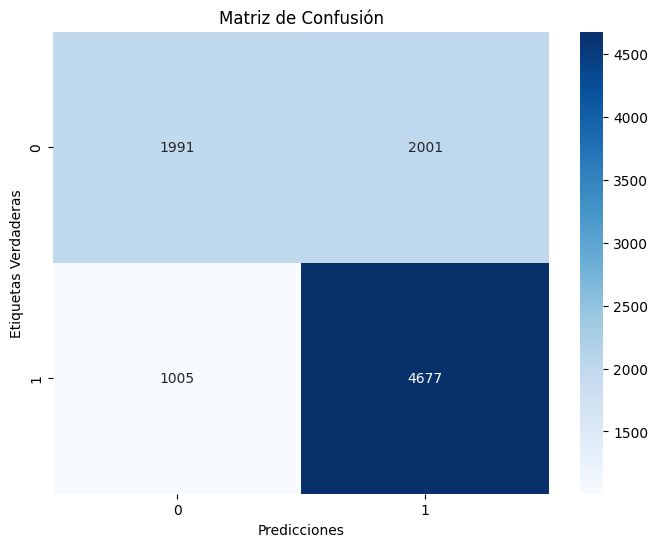

In [85]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicciones")
plt.ylabel("Etiquetas Verdaderas")
plt.title("Matriz de Confusión")

plt.show()

### Decision Tree -Arbol

In [86]:
X = df_21
y = target_21

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

tree_model = DecisionTreeClassifier()

tree_model.fit(X_train, y_train)

predictions = tree_model.predict(X_test)

accuracy_a = accuracy_score(y_test, predictions)
print("Exactitud_a (Accuracy):", accuracy_a)

precision_a = precision_score(y_test, predictions)
recall_a = recall_score(y_test, predictions)
f1_a = f1_score(y_test, predictions)

print("Precisión_a:", precision_a)
print("Exhaustividad_a (Recall):", recall_a)
print("Puntuación F1_a:", f1_a)

Exactitud_a (Accuracy): 0.8112466404796361
Precisión_a: 0.8408769448373409
Exhaustividad_a (Recall): 0.837029215065118
Puntuación F1_a: 0.8389486681954489


In [87]:
from sklearn.metrics import confusion_matrix

confusion_matrix_t = confusion_matrix(y_test, predictions)

# Imprimir la matriz de confusión
print("Matriz de Confusión:")
print(confusion_matrix_t)

Matriz de Confusión:
[[3092  900]
 [ 926 4756]]


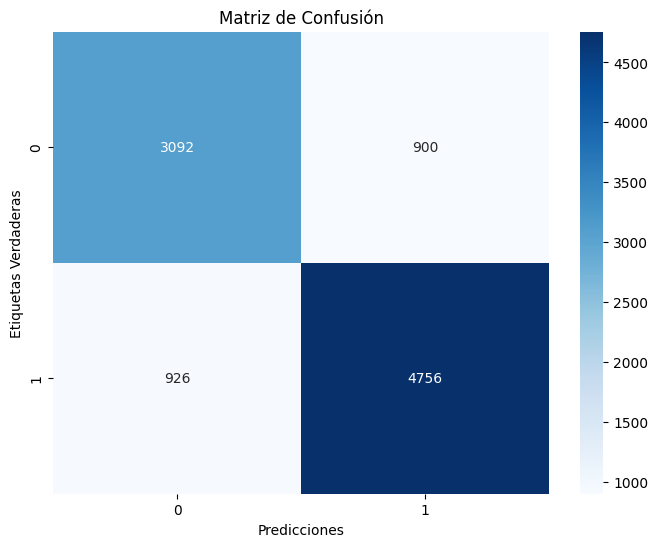

In [88]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix_t, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicciones")
plt.ylabel("Etiquetas Verdaderas")
plt.title("Matriz de Confusión")

plt.show()

### RandomForest

In [89]:
X = df_21
y = target_21

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

rf_model = RandomForestClassifier()

rf_model.fit(X_train, y_train)

predictions = rf_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, predictions)
print("Exactitud_rf (Accuracy):", accuracy_rf)

precision_rf = precision_score(y_test, predictions)
recall_rf = recall_score(y_test, predictions)
f1_rf = f1_score(y_test, predictions)

print("Precisión_rf:", precision_rf)
print("Exhaustividad_rf (Recall):", recall_rf)
print("Puntuación F1_rf:", f1_rf)

Exactitud_rf (Accuracy): 0.8551788298532148
Precisión_rf: 0.8562156764852721
Exhaustividad_rf (Recall): 0.9054910242872228
Puntuación F1_rf: 0.880164228894021


In [90]:
confusion_matrix_rf = confusion_matrix(y_test, predictions)

print("Matriz de Confusión:")
print(confusion_matrix_rf)

Matriz de Confusión:
[[3128  864]
 [ 537 5145]]


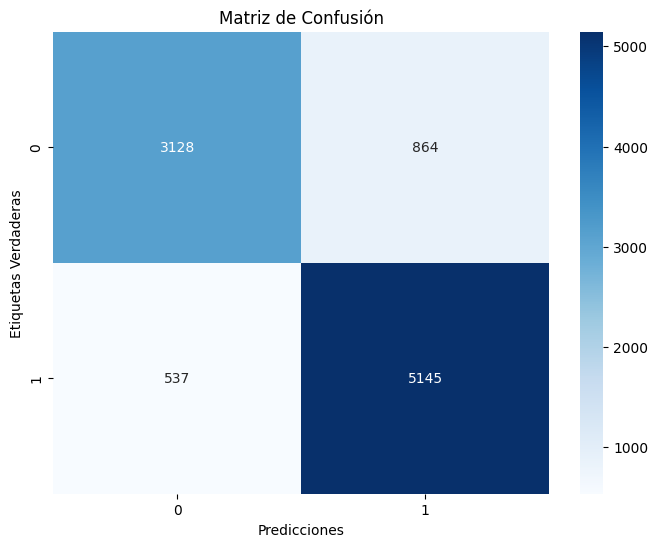

In [91]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix_rf, annot=True, fmt="d", cmap="Blues")


plt.xlabel("Predicciones")
plt.ylabel("Etiquetas Verdaderas")
plt.title("Matriz de Confusión")

plt.show()

### XGB 

In [92]:
X = df_21
y = target_21

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

xgb_model = XGBClassifier()

xgb_model.fit(X_train, y_train)

predictions = xgb_model.predict(X_test)

accuracy_xgb = accuracy_score(y_test, predictions)
print("Exactitud_xgb (Accuracy):", accuracy_xgb)

precision_xgb = precision_score(y_test, predictions)
recall_xgb = recall_score(y_test, predictions)
f1_xgb = f1_score(y_test, predictions)

print("Precisión_xgb:", precision_xgb)
print("Exhaustividad_xgb (Recall):", recall_xgb)
print("Puntuación F1_xgb:", f1_xgb)

Exactitud_xgb (Accuracy): 0.8459789125491007
Precisión_xgb: 0.8357898109580263
Exhaustividad_xgb (Recall): 0.9181626187961985
Puntuación F1_xgb: 0.8750419322375043


In [93]:
from sklearn.metrics import confusion_matrix

confusion_matrix_xgb = confusion_matrix(y_test, predictions)

print("Matriz de Confusión:")
print(confusion_matrix_xgb)

Matriz de Confusión:
[[2967 1025]
 [ 465 5217]]


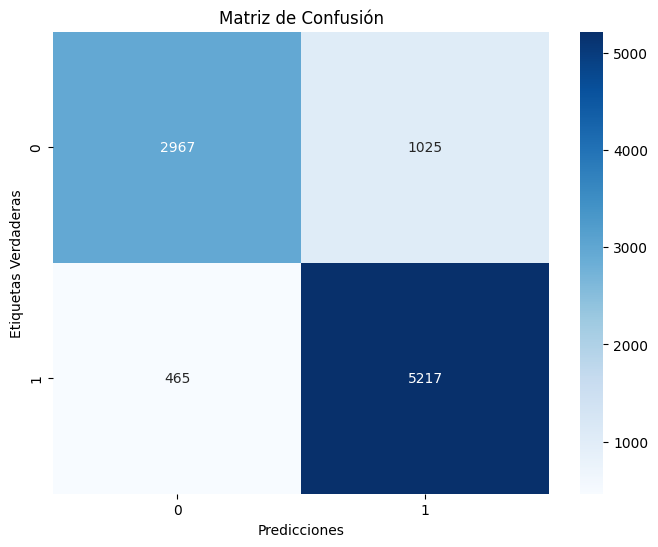

In [94]:
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix_xgb, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicciones")
plt.ylabel("Etiquetas Verdaderas")
plt.title("Matriz de Confusión")

plt.show()

In [95]:
metrics = {
    "Modelo": ["Regresión Logística_21", "Árbol de Decisión_21", "Random Forest_21", "XGBoost_21"],
    "Precisión": [precision,precision_a, precision_rf, precision_xgb],
    "Recall": [recall,recall_a, recall_rf, recall_xgb],
    "F1": [f1,f1_a, f1_rf, f1_xgb],
    "Exactitud": [accuracy,accuracy_a, accuracy_rf, accuracy_xgb]
}

df_metrics_21 = pd.DataFrame(metrics)

df_metrics_21


,Modelo,Precisión,Recall,F1,Exactitud
0,Regresión Logística_21,0.700359,0.823126,0.756796,0.689270
1,Árbol de Decisión_21,0.840877,0.837029,0.838949,0.811247
2,Random Forest_21,0.856216,0.905491,0.880164,0.855179
3,XGBoost_21,0.835790,0.918163,0.875042,0.845979


In [96]:
df_metrics

,Modelo,Precisión,Recall,F1,Exactitud
0,Regresión Logística,0.672524,0.835269,0.745113,0.664358
1,Árbol de Decisión,0.833510,0.832629,0.833069,0.804011
2,Random Forest,0.851864,0.888596,0.869842,0.843808
3,XGBoost,0.845753,0.884900,0.864883,0.837606


In [97]:
df_metrics2

,Modelo_mv,Precisión_mv,Recall_mv,F1_mv,Exactitud_mv
0,Regresión Logística,0.668216,0.835093,0.742392,0.659603
1,Árbol de Decisión,0.772968,0.769975,0.771469,0.732065
2,Random Forest,0.785950,0.795495,0.790694,0.752636
3,XGBoost,0.770105,0.906723,0.832848,0.786231


# Gráficos Ejercicio 4

In [98]:
df_c1 = df_final[['amount_tsh', 'installer', 'num_private']]

df_c1['installer'] = df_c1['installer'].astype('category')
df_c1['installer'] = df_c1['installer'].cat.codes

In [99]:
df_c2 = df_encoder[['funder', 'gps_height', 'longitude', 'latitude', 'basin','status_group_d']]

In [100]:
df_c = pd.concat([df_c1, df_c2], axis = 1)

df_c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55083 entries, 0 to 55082
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount_tsh      55083 non-null  float64
 1   installer       55083 non-null  int16  
 2   num_private     55083 non-null  int64  
 3   funder          48368 non-null  float64
 4   gps_height      48368 non-null  float64
 5   longitude       48368 non-null  float64
 6   latitude        48368 non-null  float64
 7   basin           48368 non-null  float64
 8   status_group_d  48368 non-null  float64
dtypes: float64(7), int16(1), int64(1)
memory usage: 3.5 MB


In [101]:
df_c

,amount_tsh,installer,num_private,funder,gps_height,longitude,latitude,basin,status_group_d
0,6000.0,1478,0,1.0,1390.000000,34.938093,-9.856322,1.0,1.0
1,0.0,533,0,NaN,NaN,NaN,NaN,NaN,NaN
2,25.0,1993,0,1.0,686.000000,37.460664,-3.821329,5.0,1.0
3,0.0,1803,0,1.0,263.000000,38.486161,-11.155298,7.0,0.0
4,0.0,116,0,1.0,2090.300893,31.130847,-1.825359,4.0,1.0
...,...,...,...,...,...,...,...,...,...
55078,10.0,196,0,1.0,1210.000000,37.169807,-3.253847,5.0,1.0
55079,4700.0,257,0,1.0,1212.000000,35.249991,-9.070629,6.0,1.0
55080,0.0,-1,0,NaN,NaN,NaN,NaN,NaN,NaN
55081,0.0,1188,0,1.0,242.034211,35.861315,-6.378573,6.0,1.0


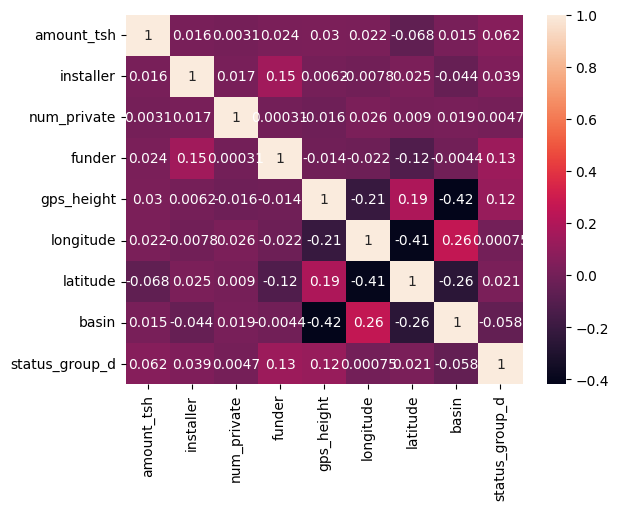

In [102]:
plt.figure()
sns.heatmap(df_c.corr(), annot = True)
plt.show()

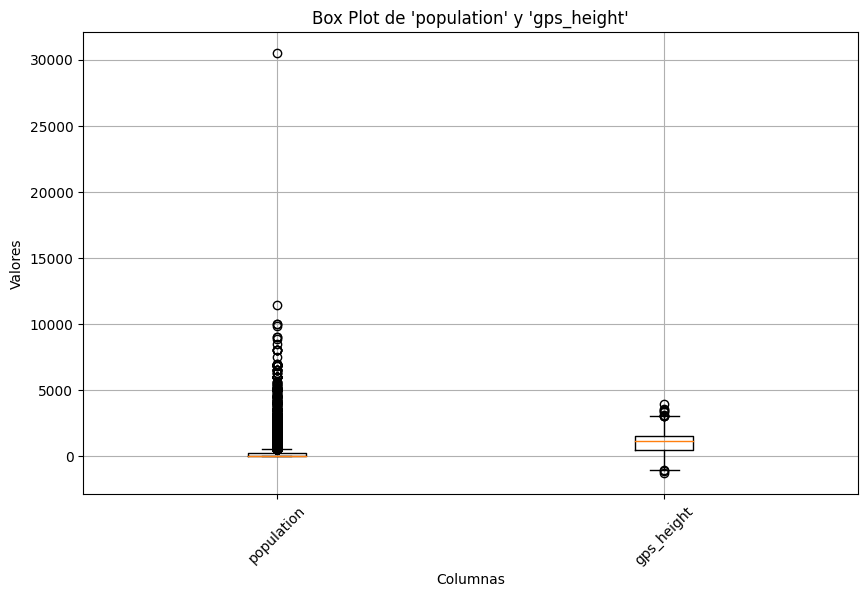

In [103]:
plt.figure(figsize=(10, 6))
plt.boxplot([df21_o['population'], df21_o['gps_height']], labels=['population', 'gps_height'])
plt.title("Box Plot de 'population' y 'gps_height'")
plt.ylabel("Valores")
plt.xlabel("Columnas")
plt.xticks(fontsize=10, rotation=45)
plt.grid(True)
plt.show()

In [104]:
Q1_pop = np.quantile(df21_o['population'], 0.25)
Q3_pop = np.quantile(df21_o['population'], 0.75)
IQR_pop = Q3_pop - Q1_pop

Q1_gps = np.quantile(df21_o['gps_height'], 0.25)
Q3_gps = np.quantile(df21_o['gps_height'], 0.75)
IQR_gps = Q3_gps - Q1_gps

limite_inf_pop = Q1_pop - 1.5 * IQR_pop
limite_sup_pop = Q3_pop + 1.5 * IQR_pop

limite_inf_gps = Q1_gps - 1.5 * IQR_gps
limite_sup_gps = Q3_gps + 1.5 * IQR_gps

df21_o.drop(df21_o[df21_o["population"] < limite_inf_pop].index, inplace=True)
df21_o.drop(df21_o[df21_o["population"] > limite_sup_pop].index, inplace=True)

df21_o.drop(df21_o[df21_o["gps_height"] < limite_inf_gps].index, inplace=True)
df21_o.drop(df21_o[df21_o["gps_height"] > limite_sup_gps].index, inplace=True)

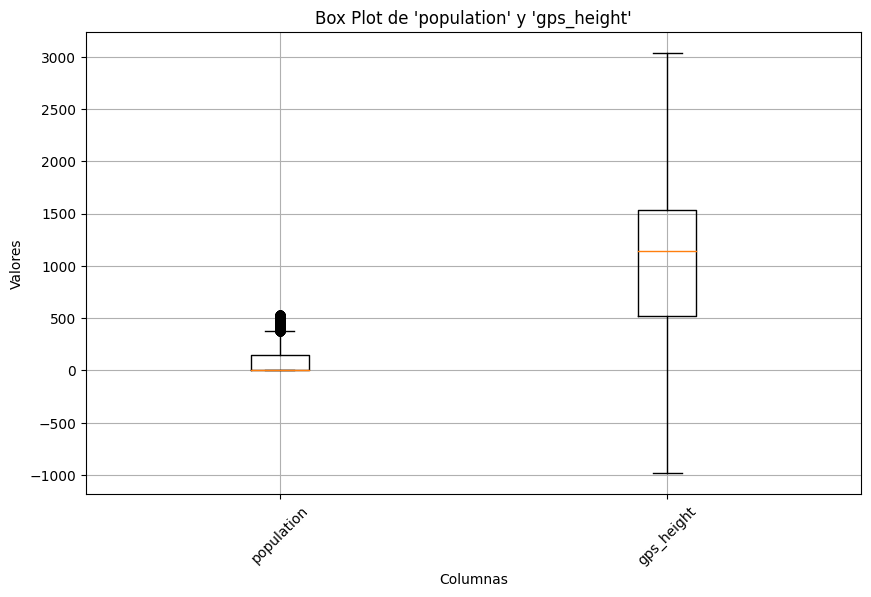

In [105]:
plt.figure(figsize=(10, 6))
plt.boxplot([df21_o['population'], df21_o['gps_height']], labels=['population', 'gps_height'])
plt.title("Box Plot de 'population' y 'gps_height'")
plt.ylabel("Valores")
plt.xlabel("Columnas")
plt.xticks(fontsize=10, rotation=45)
plt.grid(True)
plt.show()

In [106]:
target_21o = df21_o.copy()

In [107]:
target_21o.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 44777 entries, 0 to 55082
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   amount_tsh             44777 non-null  float64
 1   funder                 44777 non-null  int64  
 2   gps_height             44777 non-null  float64
 3   installer              44777 non-null  int16  
 4   longitude              44777 non-null  float64
 5   latitude               44777 non-null  float64
 6   basin                  44777 non-null  int8   
 7   region                 44777 non-null  int8   
 8   population             44777 non-null  int64  
 9   public_meeting         44777 non-null  int64  
 10  scheme_management      44777 non-null  int8   
 11  permit                 44777 non-null  int64  
 12  construction_year      44777 non-null  float64
 13  extraction_type        44777 non-null  int8   
 14  management_group       44777 non-null  int8   
 15  pa

In [108]:
target_21o = target_21o['status_group_d']

In [109]:
df21_o.drop(columns = 'status_group_d', inplace = True)

In [110]:
X = df21_o
y = target_21o

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

xgb_model = XGBClassifier()

xgb_model.fit(X_train, y_train)

predictions = xgb_model.predict(X_test)

accuracy_xgbwo = accuracy_score(y_test, predictions)
print("Exactitud_xgb (Accuracy):", accuracy_xgbwo)

precision_xgbwo = precision_score(y_test, predictions)
recall_xgbwo = recall_score(y_test, predictions)
f1_xgbwo = f1_score(y_test, predictions)

print("Precisión_xgb:", precision_xgbwo)
print("Exhaustividad_xgb (Recall):", recall_xgbwo)
print("Puntuación F1_xgb:", f1_xgbwo)

Exactitud_xgb (Accuracy): 0.8567440821795445
Precisión_xgb: 0.8487277797141861
Exhaustividad_xgb (Recall): 0.9214758751182592
Puntuación F1_xgb: 0.8836070035380568


In [111]:
metrics_o = {
    "Modelo": ["Sin outliers", "con"],
    "Precisión": [precision_xgbwo, precision_xgb],
    "Recall": [recall_xgbwo, recall_xgb],
    "F1": [f1_xgbwo, f1_xgb],
    "Exactitud": [accuracy_xgbwo, accuracy_xgb]
}

df_metrics_21_o = pd.DataFrame(metrics_o)

df_metrics_21_o

,Modelo,Precisión,Recall,F1,Exactitud
0,Sin outliers,0.848728,0.921476,0.883607,0.856744
1,con,0.835790,0.918163,0.875042,0.845979
